# Punto 1 — Generación de texto a nivel de **carácter** con un Transformer tipo **Llama**

UNIVERSIDAD AUTÓNOMA DE OCCIDENTE — Inteligencia Artificial Generativa 2026-2S  
Entregable: *Modelos Generativos de Texto Basados en la Arquitectura Transformer*  
**Integrantes:** Sergio Gómez — Valeria Franco

**Objetivo:** cambiar el corpus de Shakespeare por otro (aquí *Don Quijote*) y entrenar un
modelo *Char GPT* cuya arquitectura sea la de **Llama** (RMSNorm + RoPE + SwiGLU, sin bias),
evaluando con métricas adecuadas para modelos de lenguaje.

> Ejecutar en Colab con **GPU (T4)**: *Entorno de ejecución → Cambiar tipo → GPU*.

In [1]:
import os, sys, re, math, time, collections
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Modo rápido (solo para pruebas locales sin GPU): RAPIDO=1 reduce corpus y épocas
RAPIDO = os.environ.get("RAPIDO", "0") == "1"
tf.random.set_seed(42); np.random.seed(42)
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Corpus: *Don Quijote de la Mancha* (Miguel de Cervantes)

Reemplazamos las obras de Shakespeare por el texto completo de **Don Quijote de la Mancha**
(Proyecto Gutenberg, libro #2000, dominio público). Es un corpus en **español** de ~2 millones
de caracteres, de tamaño comparable al de Shakespeare (~1.1 M), con diálogos y narración,
lo que lo hace adecuado para un modelo de lenguaje pequeño.

In [2]:
url = "https://www.gutenberg.org/cache/epub/2000/pg2000.txt"
filepath = tf.keras.utils.get_file("quijote.txt", url)
with open(filepath, encoding="utf-8") as f:
    raw = f.read()

# Quitamos la cabecera y la licencia de Gutenberg
start = raw.find("*** START OF"); start = raw.find("\n", start) + 1
end = raw.find("*** END OF")
text = raw[start:end].strip()
text = re.sub(r"\r", "", text)
text = re.sub(r"(?<!\n)\n(?!\n)", " ", text)   # une las líneas cortadas a ~70 columnas
text = re.sub(r"\n{2,}", "\n", text)           # un salto de línea = cambio de párrafo
text = re.sub(r" {2,}", " ", text)
if RAPIDO:
    text = text[:200_000]
print(f"Caracteres: {len(text):,}")
print(text[5000:5600])

2225803/2225803 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Caracteres: 2,104,974
s los que llevaban a don Quijote
De la pendencia que don Quijote tuvo con el cabrero, con la rara aventura de los deceplinantes, a quien dio felice fin a costa de su sudor
Segunda parte del ingenioso caballero don Quijote de la Mancha
 Tasa
 Fee de erratas
 Aprobaciones
 Dedicatoria, al conde de Lemos
 Prólogo al lector
De lo que el cura y el barbero pasaron con don Quijote cerca de su enfermedad
Que trata de la notable pendencia que Sancho Panza tuvo con la sobrina y ama de don Quijote, con otros sujetos graciosos
Del ridículo razonamiento que pasó entre don Quijote, Sancho Panza y el bachill


## 2. Tokenización a nivel de carácter

Igual que en el notebook de clase usamos `TextVectorization(split="character")`, en
minúsculas, y descartamos los tokens 0 (`PAD`) y 1 (`UNK`).

In [3]:
text_vec_layer = tf.keras.layers.TextVectorization(split="character", standardize="lower")
text_vec_layer.adapt([text])
vocab = text_vec_layer.get_vocabulary()
encoded = text_vec_layer([text])[0].numpy() - 2      # quitamos PAD/UNK
n_tokens = len(vocab) - 2
print("Vocabulario (caracteres):", n_tokens)
print("".join(vocab[2:]))

Vocabulario (caracteres): 68
 eaosnrlduitcm,pqybhvgíjó.fáé—z
;ñ:ú?¿'!¡x»"É-ü)(«ÁÍ1ÚÓï6ùw]40àÑ7532


Particionamos el texto de forma **contigua** (90 % entrenamiento, 5 % validación,
5 % prueba) para que la evaluación sea sobre texto nunca visto.

In [4]:
def to_dataset(sequence, length, shift=1, shuffle=False, seed=None, batch_size=64):
    """Ventanas de length+1 tokens -> (entrada = x[:-1], objetivo = x[1:])."""
    ds = tf.data.Dataset.from_tensor_slices(sequence)
    ds = ds.window(length + 1, shift=shift, drop_remainder=True)
    ds = ds.flat_map(lambda w: w.batch(length + 1))
    if shuffle:
        ds = ds.shuffle(20_000, seed=seed)
    ds = ds.batch(batch_size)
    return ds.map(lambda w: (w[:, :-1], w[:, 1:])).prefetch(tf.data.AUTOTUNE)

LENGTH = 128                     # contexto del modelo (caracteres)
n = len(encoded)
i_tr, i_va = int(n * 0.90), int(n * 0.95)
# shift=LENGTH//4 para que una época no tenga millones de ventanas casi idénticas
train_set = to_dataset(encoded[:i_tr], LENGTH, shift=LENGTH // 4, shuffle=True, seed=42)
valid_set = to_dataset(encoded[i_tr:i_va], LENGTH, shift=LENGTH)
test_set = to_dataset(encoded[i_va:], LENGTH, shift=LENGTH)

for x, y in train_set.take(1):
    dec = lambda ids: "".join(vocab[i + 2] for i in ids)
    print("Entrada :", repr(dec(x[0].numpy()[:60])))
    print("Objetivo:", repr(dec(y[0].numpy()[:60])))

Entrada : ' caballeriza.\ny, habiendo andado como dos millas, descubrió '
Objetivo: 'caballeriza.\ny, habiendo andado como dos millas, descubrió d'


## Arquitectura Transformer tipo Llama

El Char-Transformer de clase usa la parte **decodificadora** de un Transformer "clásico"
(GPT-2/Vaswani): embeddings posicionales aprendidos, `LayerNormalization` *post-norm*,
FFN con ReLU. La familia **Llama** (Touvron et al., 2023) introduce cuatro cambios que aquí
implementamos desde cero en Keras:

| Componente | Transformer clásico | Llama (este notebook) |
|---|---|---|
| Normalización | LayerNorm (post-norm) | **RMSNorm** (pre-norm) |
| Posición | Embedding posicional absoluto sumado | **RoPE** – rotación de *queries/keys* |
| Red feed-forward | Dense → ReLU → Dense | **SwiGLU**: `W2(SiLU(W1·x) ⊙ W3·x)` |
| Sesgos (*bias*) | Sí | **No** (todas las capas lineales sin bias) |

Además la atención es **causal** (cada posición solo ve las anteriores), por lo que el modelo
es autorregresivo: `P(x_t | x_<t)`.

In [5]:
import keras
from keras import layers, ops


@keras.saving.register_keras_serializable(package="llama")
class RMSNorm(layers.Layer):
    """Root Mean Square Norm: x / sqrt(mean(x^2) + eps) * g  (sin centrar ni bias)."""
    def __init__(self, eps=1e-6, **kwargs):
        super().__init__(**kwargs)
        self.eps = eps

    def build(self, input_shape):
        self.scale = self.add_weight(name="scale", shape=(input_shape[-1],), initializer="ones")

    def call(self, x):
        ms = ops.mean(ops.square(x), axis=-1, keepdims=True)
        return x * ops.rsqrt(ms + self.eps) * self.scale

    def get_config(self):
        return {**super().get_config(), "eps": self.eps}


def rope(x, base=10000.0):
    """Rotary Positional Embedding. x: (batch, heads, seq, head_dim)."""
    seq_len, head_dim = ops.shape(x)[2], ops.shape(x)[3]
    half = head_dim // 2
    inv_freq = 1.0 / (base ** (ops.cast(ops.arange(half), "float32") / half))
    pos = ops.cast(ops.arange(seq_len), "float32")
    angles = ops.einsum("i,j->ij", pos, inv_freq)            # (seq, half)
    cos, sin = ops.cos(angles), ops.sin(angles)
    cos, sin = ops.cast(cos, x.dtype), ops.cast(sin, x.dtype)
    x1, x2 = x[..., :half], x[..., half:]
    return ops.concatenate([x1 * cos - x2 * sin, x1 * sin + x2 * cos], axis=-1)


@keras.saving.register_keras_serializable(package="llama")
class CausalSelfAttentionRoPE(layers.Layer):
    """Atención multi-cabeza causal con RoPE y proyecciones sin bias."""
    def __init__(self, d_model, n_heads, dropout=0.0, **kwargs):
        super().__init__(**kwargs)
        self.d_model, self.n_heads, self.dropout_rate = d_model, n_heads, dropout
        self.head_dim = d_model // n_heads
        self.wq = layers.Dense(d_model, use_bias=False)
        self.wk = layers.Dense(d_model, use_bias=False)
        self.wv = layers.Dense(d_model, use_bias=False)
        self.wo = layers.Dense(d_model, use_bias=False)
        self.drop = layers.Dropout(dropout)

    def _split(self, x, b, t):
        x = ops.reshape(x, (b, t, self.n_heads, self.head_dim))
        return ops.transpose(x, (0, 2, 1, 3))                   # (b, h, t, hd)

    def call(self, x, training=False):
        b, t = ops.shape(x)[0], ops.shape(x)[1]
        q = rope(self._split(self.wq(x), b, t))
        k = rope(self._split(self.wk(x), b, t))
        v = self._split(self.wv(x), b, t)
        scores = ops.matmul(q, ops.transpose(k, (0, 1, 3, 2))) / ops.sqrt(ops.cast(self.head_dim, x.dtype))
        mask = ops.tril(ops.ones((t, t), dtype="bool"))          # máscara causal
        scores = ops.where(mask, scores, ops.cast(-1e9, scores.dtype))
        att = self.drop(ops.softmax(scores, axis=-1), training=training)
        out = ops.transpose(ops.matmul(att, v), (0, 2, 1, 3))
        return self.wo(ops.reshape(out, (b, t, self.d_model)))

    def get_config(self):
        return {**super().get_config(), "d_model": self.d_model, "n_heads": self.n_heads,
                "dropout": self.dropout_rate}


@keras.saving.register_keras_serializable(package="llama")
class SwiGLU(layers.Layer):
    """FFN de Llama: W2( SiLU(W1 x) * W3 x ), sin bias."""
    def __init__(self, d_model, hidden, **kwargs):
        super().__init__(**kwargs)
        self.d_model, self.hidden = d_model, hidden
        self.w1 = layers.Dense(hidden, use_bias=False)
        self.w3 = layers.Dense(hidden, use_bias=False)
        self.w2 = layers.Dense(d_model, use_bias=False)

    def call(self, x):
        return self.w2(ops.silu(self.w1(x)) * self.w3(x))

    def get_config(self):
        return {**super().get_config(), "d_model": self.d_model, "hidden": self.hidden}


@keras.saving.register_keras_serializable(package="llama")
class LlamaBlock(layers.Layer):
    """Bloque decodificador Llama (pre-norm + conexiones residuales)."""
    def __init__(self, d_model, n_heads, ffn_hidden, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.cfg = dict(d_model=d_model, n_heads=n_heads, ffn_hidden=ffn_hidden, dropout=dropout)
        self.norm1, self.norm2 = RMSNorm(), RMSNorm()
        self.attn = CausalSelfAttentionRoPE(d_model, n_heads, dropout)
        self.ffn = SwiGLU(d_model, ffn_hidden)
        self.drop = layers.Dropout(dropout)

    def call(self, x, training=False):
        x = x + self.drop(self.attn(self.norm1(x), training=training), training=training)
        x = x + self.drop(self.ffn(self.norm2(x)), training=training)
        return x

    def get_config(self):
        return {**super().get_config(), **self.cfg}


def build_llama(vocab_size, d_model=256, n_heads=8, n_layers=6, ffn_hidden=None, dropout=0.1):
    """Modelo completo: Embedding -> N x LlamaBlock -> RMSNorm -> Dense(vocab) (logits)."""
    ffn_hidden = ffn_hidden or int(8 * d_model / 3)          # proporción usada en Llama
    inputs = keras.Input(shape=(None,), dtype="int32")
    x = layers.Embedding(vocab_size, d_model)(inputs)        # sin embedding posicional: RoPE
    x = layers.Dropout(dropout)(x)
    for i in range(n_layers):
        x = LlamaBlock(d_model, n_heads, ffn_hidden, dropout, name=f"llama_block_{i}")(x)
    x = RMSNorm(name="final_norm")(x)
    logits = layers.Dense(vocab_size, use_bias=False, name="lm_head")(x)
    return keras.Model(inputs, logits, name="llama_lm")

## 3. Construcción y entrenamiento del Char-Llama

Hiperparámetros: `d_model=256`, 8 cabezas, 6 bloques, FFN SwiGLU de 682 unidades,
contexto de 128 caracteres. Optimizador **AdamW** con *warmup* + decaimiento coseno
y *gradient clipping* (configuración típica de Llama).

In [6]:
EPOCHS = 2 if RAPIDO else 8
cfg = dict(d_model=64, n_heads=4, n_layers=2) if RAPIDO else dict(d_model=256, n_heads=8, n_layers=6)
model = build_llama(n_tokens, dropout=0.1, **cfg)

steps_per_epoch = sum(1 for _ in train_set)
lr = keras.optimizers.schedules.CosineDecay(1e-4, decay_steps=EPOCHS * steps_per_epoch,
                                            warmup_target=6e-4, warmup_steps=min(500, steps_per_epoch))
model.compile(optimizer=keras.optimizers.AdamW(lr, weight_decay=0.1, clipnorm=1.0),
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5")])
model.summary()

Model: "llama_lm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, None)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, None, 256)      │        17,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, None, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ llama_block_0 (LlamaBlock)      │ (None, None, 256)      │       786,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ llama_block_1 (LlamaBlock)      │ (None, None, 256)      │       786,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ llama_block_2 (LlamaBlock)      │ (None, None, 256)      │       786,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ llama_block_3 (LlamaBlock)      │ (None, None, 256)      │       786,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ llama_block_4 (LlamaBlock)      │ (None, None, 256)      │       786,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ llama_block_5 (LlamaBlock)      │ (None, None, 256)      │       786,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ final_norm (RMSNorm)            │ (None, None, 256)      │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lm_head (Dense)                 │ (None, None, 68)       │        17,408 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,753,664 (18.13 MB)

 Trainable params: 4,753,664 (18.13 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
             keras.callbacks.ModelCheckpoint("char_llama_quijote.keras", monitor="val_loss", save_best_only=True)]
t0 = time.time()
history = model.fit(train_set, validation_data=valid_set, epochs=EPOCHS, callbacks=callbacks)
print(f"Tiempo de entrenamiento: {(time.time() - t0) / 60:.1f} min")

Epoch 1/8
    925/Unknown 169s 134ms/step - accuracy: 0.3671 - loss: 2.1440 - top5: 0.7337

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


925/925 ━━━━━━━━━━━━━━━━━━━━ 176s 142ms/step - accuracy: 0.4648 - loss: 1.7279 - top5: 0.8147 - val_accuracy: 0.5754 - val_loss: 1.3307 - val_top5: 0.8778
Epoch 2/8
925/925 ━━━━━━━━━━━━━━━━━━━━ 125s 129ms/step - accuracy: 0.5898 - loss: 1.2718 - top5: 0.8865 - val_accuracy: 0.6048 - val_loss: 1.2302 - val_top5: 0.8898
Epoch 3/8
925/925 ━━━━━━━━━━━━━━━━━━━━ 128s 132ms/step - accuracy: 0.6156 - loss: 1.1813 - top5: 0.8975 - val_accuracy: 0.6186 - val_loss: 1.1893 - val_top5: 0.8951
Epoch 4/8
925/925 ━━━━━━━━━━━━━━━━━━━━ 127s 132ms/step - accuracy: 0.6310 - loss: 1.1280 - top5: 0.9039 - val_accuracy: 0.6274 - val_loss: 1.1631 - val_top5: 0.8978
Epoch 5/8
925/925 ━━━━━━━━━━━━━━━━━━━━ 128s 132ms/step - accuracy: 0.6427 - loss: 1.0876 - top5: 0.9086 - val_accuracy: 0.6326 - val_loss: 1.1502 - val_top5: 0.8991
Epoch 6/8
925/925 ━━━━━━━━━━━━━━━━━━━━ 127s 132ms/step - accuracy: 0.6525 - loss: 1.0550 - top5: 0.9124 - val_accuracy: 0.6368 - val_loss: 1.1433 - val_top5: 0.9011
Epoch 7/8
925/925 ━━

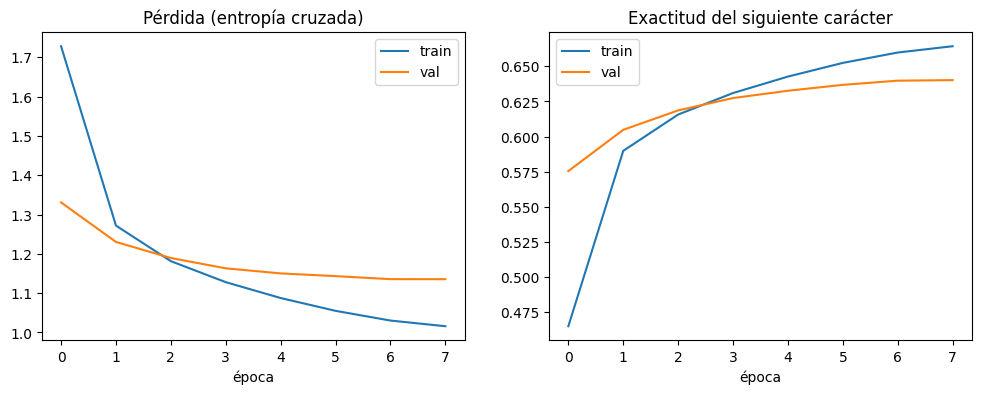

In [8]:
# Para recargar el modelo guardado:
# model = keras.models.load_model("char_llama_quijote.keras")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="val")
ax[0].set_title("Pérdida (entropía cruzada)"); ax[0].set_xlabel("época"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train"); ax[1].plot(history.history["val_accuracy"], label="val")
ax[1].set_title("Exactitud del siguiente carácter"); ax[1].set_xlabel("época"); ax[1].legend()
plt.show()

## 4. Evaluación cuantitativa

Métricas estándar para modelos de lenguaje evaluadas en el conjunto de **prueba**:

* **Entropía cruzada** `H` (nats/carácter): pérdida media de predicción del siguiente carácter.
* **Perplejidad** `PPL = e^H`: número efectivo de caracteres entre los que el modelo "duda".
  Un modelo aleatorio uniforme tendría `PPL = |V|`.
* **Bits por carácter** `BPC = H / ln 2`: métrica clásica de modelos a nivel de carácter
  (≈ tasa de compresión). Los Char-RNN típicos están entre 1.3–2.0 BPC.
* **Exactitud top-1 y top-5** del siguiente carácter.

Como línea base calculamos un modelo de **unigramas** (frecuencia de caracteres) para tener una
referencia de cuánto aprende el Transformer.

In [9]:
test_loss, test_acc, test_top5 = model.evaluate(test_set, verbose=0)
ppl, bpc = math.exp(test_loss), test_loss / math.log(2)

# Línea base: unigramas de caracteres estimados en train
counts = np.bincount(encoded[:i_tr], minlength=n_tokens) + 1
p_uni = counts / counts.sum()
h_uni = -np.mean(np.log(p_uni[encoded[i_va:]]))

print(f"{'Métrica':<28}{'Char-Llama':>12}{'Unigramas':>12}")
print(f"{'Entropía cruzada (nats)':<28}{test_loss:>12.3f}{h_uni:>12.3f}")
print(f"{'Perplejidad':<28}{ppl:>12.2f}{math.exp(h_uni):>12.2f}")
print(f"{'Bits por carácter (BPC)':<28}{bpc:>12.3f}{h_uni / math.log(2):>12.3f}")
print(f"{'Exactitud top-1':<28}{test_acc:>12.3f}{p_uni.max():>12.3f}")
print(f"{'Exactitud top-5':<28}{test_top5:>12.3f}{np.sort(p_uni)[-5:].sum():>12.3f}")
print(f"Perplejidad de un modelo uniforme: {n_tokens}")

Métrica                       Char-Llama   Unigramas
Entropía cruzada (nats)            1.129       2.953
Perplejidad                         3.09       19.16
Bits por carácter (BPC)            1.629       4.260
Exactitud top-1                    0.642       0.181
Exactitud top-5                    0.905       0.514
Perplejidad de un modelo uniforme: 68


## 5. Generación de texto

Generamos de forma autorregresiva muestreando de `softmax(logits / T)`.
La **temperatura** `T` controla la diversidad: `T→0` es casi *greedy* (repetitivo y "seguro"),
`T>1` aplana la distribución (más creativo pero con más errores).

In [10]:
char2id = {c: i - 2 for i, c in enumerate(vocab) if i >= 2}

def generate(prompt, n_chars=400, temperature=0.8, seed=42):
    rng = np.random.default_rng(seed)
    ids = [char2id.get(c, 0) for c in prompt.lower()]
    for _ in range(n_chars):
        ctx = np.array([ids[-LENGTH:]], dtype="int32")
        logits = model(ctx, training=False)[0, -1].numpy().astype("float64") / temperature
        p = np.exp(logits - logits.max()); p /= p.sum()
        ids.append(int(rng.choice(len(p), p=p)))
    return "".join(vocab[i + 2] for i in ids)

prompt = "en un lugar de la mancha"
for T in [0.2, 0.8, 1.2]:
    print(f"===== Temperatura {T} =====")
    print(generate(prompt, temperature=T), "\n")

===== Temperatura 0.2 =====
en un lugar de la mancha, y el caballero de la triste figura, y el de la caballería andante estaba en la cabeza, y a la de la caballería andante estaba en la cabeza, y el cual se le había de parar a su padre y de la mano a su amo, y la duquesa y de la mancha, y el caballero de la triste figura, y de la cual se le dieron con el caballero de la triste figura, y el primero que le había de dar con el mundo, y que le diese a  

===== Temperatura 0.8 =====
en un lugar de la mancha, y el parecer de mi cuerpo sacó su amo, y no le salteó la noche, y en lo de la mano en el mundo a quien tan venturoso como el señor don quijote de la mancha, y que si su majestad y la poesía en el suelo, se acomodó en su muerte, le dijo: — vencido a vuestra merced se estaba admirado de dar palabras, porque en este mayor parte de tu carne y de ver la mano, y es muy diciendo, mientras que en ella l 

===== Temperatura 1.2 =====
en un lugar de la mancha. hidólo las barbas que me escuchada d

### Métricas sobre el texto generado

La perplejidad mide qué tan bien el modelo **predice** texto real; para valorar el texto
**generado** usamos:

* **% palabras válidas**: fracción de palabras generadas que existen en el vocabulario del
  Quijote (a nivel de carácter el modelo debe *aprender a deletrear*).
* **distinct-1 / distinct-2**: diversidad léxica (palabras y bigramas únicos).
* **Tasa de repetición de 4-gramas**: detecta bucles degenerados.

In [ ]:
def distinct_n(tokens, n):
    """Proporción de n-gramas únicos (diversidad léxica; 1.0 = sin repeticiones)."""
    grams = [tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]
    return len(set(grams)) / max(len(grams), 1)


corpus_words = set(re.findall(r"[a-záéíóúüñ]+", text.lower()))

def valid_word_ratio(generated):
    """% de palabras generadas que existen en el vocabulario del corpus (ortografía)."""
    words = re.findall(r"[a-záéíóúüñ]+", generated.lower())
    return sum(w in corpus_words for w in words) / max(len(words), 1)


def rep_rate(tokens, n=4):
    """% de 4-gramas repetidos dentro del mismo texto (detecta bucles)."""
    return 1 - distinct_n(tokens, n)

In [12]:
prompts = ["en un lugar de la mancha", "dijo sancho", "—señor caballero", "la hermosa dulcinea"]
rows = []
for T in [0.2, 0.8, 1.2]:
    gens = [generate(p, 200, T, seed=s)[len(p):] for s, p in enumerate(prompts)]
    toks = [w for g in gens for w in re.findall(r"\w+", g)]
    rows.append((T, np.mean([valid_word_ratio(g) for g in gens]), distinct_n(toks, 1),
                 distinct_n(toks, 2), np.mean([rep_rate(re.findall(r"\w+", g)) for g in gens])))

ref = re.findall(r"\w+", text[int(len(text) * 0.95):][:5000].lower())
print(f"{'T':>5}{'%válidas':>10}{'dist-1':>9}{'dist-2':>9}{'rep-4g':>9}")
for r in rows:
    print(f"{r[0]:>5}{r[1]:>10.3f}{r[2]:>9.3f}{r[3]:>9.3f}{r[4]:>9.3f}")
print(f"{'real':>5}{1.0:>10.3f}{distinct_n(ref[:len(toks)], 1):>9.3f}{distinct_n(ref[:len(toks)], 2):>9.3f}")

    T  %válidas   dist-1   dist-2   rep-4g
  0.2     0.987    0.405    0.713    0.039
  0.8     0.980    0.627    0.941    0.000
  1.2     0.892    0.727    0.993    0.000
 real     1.000    0.640    0.891


## 6. Conclusiones

**Resultados obtenidos** (ejecución en Colab, GPU T4, 8 épocas, 17.8 min de entrenamiento):

| Métrica (conjunto de prueba) | Char-Llama | Unigramas |
|---|---|---|
| Entropía cruzada (nats) | 1.129 | 2.953 |
| Perplejidad | **3.09** | 19.16 |
| Bits por carácter | **1.63** | 4.26 |
| Exactitud top-1 | **0.642** | 0.181 |
| Exactitud top-5 | **0.905** | 0.514 |

La pérdida de validación bajó de 1.33 (época 1) a 1.13 (época 8) sin sobreajuste. Ejemplo generado con `T = 0.2`:

> *en un lugar de la mancha, y el caballero de la triste figura, y el de la caballería andante estaba en la cabeza […] y el caballero de la triste figura…*

* El Char-Llama reduce la perplejidad de 19.2 (unigramas) a 3.09 y queda en 1.63 BPC, dentro del rango típico de los Char-RNN: el modelo
  aprende ortografía, puntuación, el uso del guion de diálogo y nombres propios (Sancho, Quijote,
  Dulcinea) solo a partir de caracteres.
* **RoPE** permite prescindir del embedding posicional absoluto y codifica posiciones relativas en
  el producto `q·k`; **RMSNorm pre-norm** y **SwiGLU** son los cambios que, según el artículo de LLaMA,
  estabilizan el entrenamiento y mejoran la calidad frente al decodificador clásico.
* **Texto generado** (palabras válidas / distinct-2 / 4-gramas repetidos): con `T = 0.2` 98.7 % /
  0.71 / 3.9 %, frases correctas pero repetitivas; con `T = 1.2` 89.2 % / 0.99 / 0 %, más variado
  pero con palabras inventadas ("descomunastro"). `T = 0.8` da el mejor equilibrio: 98.0 % de
  palabras válidas y distinct-1 = 0.63, casi igual al texto real (0.64).
* Limitación: a nivel de carácter el contexto de 128 caracteres equivale a ~20 palabras, por lo que la
  coherencia a nivel de oración/párrafo es limitada (ver Punto 2).